In [1]:
import sys
sys.path.append('../src/')
sys.path.append('../src/optimizers/')
sys.path.append('../src/models/')

In [2]:
import torch
import torch.nn as nn
from torch.utils.data import DataLoader

# from torchvision.models import resnet18, resnet34
from torchvision.datasets import CIFAR10
import torchvision.transforms as transforms

import math
import time
import os
import random
import numpy as np
import pandas as pd
from typing import Callable, Any

from tensorion import Tensorion
import resnet

In [3]:
device = torch.device('cuda') if torch.cuda.is_available() else torch.device('cpu')

device

device(type='cuda')

In [4]:
def set_global_seed(seed: int) -> torch.Generator:
    """
    Set global seed for reproducibility.
    """
    
    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    np.random.seed(seed)
    random.seed(seed)
    # torch.use_deterministic_algorithms(True) # если нужно гарантировать 1000% воспроизводимость

    # Для Dataloader
    g = torch.Generator()
    g.manual_seed(seed)
    
    return g

# Для каждого woerker в Daaloader
def seed_worker(worker_id):
    worker_seed = torch.initial_seed() % 2**32
    np.random.seed(worker_seed)
    random.seed(worker_seed)

In [5]:
transform_train = transforms.Compose([
        # transforms.Resize(256),
        # transforms.CenterCrop(224),
        transforms.RandomCrop(32, padding=4),
        transforms.RandomHorizontalFlip(),
        transforms.ToTensor(),
        transforms.Normalize((0.4914, 0.4822, 0.4465), (0.2023, 0.1994, 0.2010)),
    ])

transform_test = transforms.Compose([
        # transforms.Resize(256),
        # transforms.CenterCrop(224),
        transforms.ToTensor(),
        transforms.Normalize((0.4914, 0.4822, 0.4465), (0.2023, 0.1994, 0.2010)),
    ])

In [6]:
train_data = CIFAR10(root='./data',
                     train=True,
                     download=True,
                     transform=transform_train,
                     )

test_data = CIFAR10(root='./data',
                     train=False,
                     download=True,
                     transform=transform_test,
                     )

In [7]:
@torch.no_grad()
def test(model: nn.Module, test_loader: DataLoader, loss_fn: Callable[[torch.Tensor, torch.Tensor], torch.Tensor],  device: str) -> tuple:
    model.eval()
    epoch_loss = torch.zeros((1, ), device=device)
    epoch_accuracy = torch.zeros((1, ), device=device)
    num_samples = 0

    for (inp, labels) in test_loader:
        bs = labels.shape[0]
        inp = inp.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        preds = model(inp)
        
        epoch_loss += loss_fn(preds, labels) * bs

        preds = torch.argmax(preds, dim=-1)
        epoch_accuracy += (preds == labels).float().sum()
        
        num_samples += bs

    epoch_loss = epoch_loss.item() / num_samples
    epoch_accuracy = epoch_accuracy.item() / num_samples
    
    return epoch_accuracy, epoch_loss


def train_epoch(model: nn.Module, optimizer: torch.optim.Optimizer, scheduler, train_loader :DataLoader, loss_fn: Callable[[torch.Tensor, torch.Tensor], torch.Tensor], device: str) -> float:
    model.train()
    epoch_loss = torch.zeros((1, ), device=device)
    num_samples = 0

    for (inp, labels) in train_loader:
        bs = labels.shape[0]
        inp = inp.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        optimizer.zero_grad()

        preds = model(inp)
        loss = loss_fn(preds, labels)
        loss.backward()
        optimizer.step()
        
        epoch_loss = epoch_loss + loss.detach() * bs
        num_samples += bs

    scheduler.step()
    epoch_loss = epoch_loss.item() / num_samples

    return epoch_loss


def train_loop(model, train_loader, test_loader, optimizer, scheduler, criterion, device, num_epochs):
    train_losses = []
    test_losses = []
    accs = []
    lr_diffs = []


    acc, test_loss = test(model=model,
                            test_loader=test_loader,
                            loss_fn=criterion,
                            device=device)
    print(f'Epoch {0:2} ||  Accuracy = {acc:.4f} || test_loss = {test_loss:.6f}')

    for epoch in range(1, num_epochs + 1):
        train_loss = train_epoch(model=model,
                                optimizer=optimizer,
                                train_loader=train_loader,
                                loss_fn=criterion,
                                device=device,
                                scheduler=scheduler)
        lr = scheduler.get_last_lr()

        acc, test_loss = test(model=model,
                            test_loader=test_loader,
                            loss_fn=criterion,
                            device=device)
                

        print(f'Epoch {epoch:2} ||  Accuracy = {acc:.4f} || test_loss = {test_loss:.6f} || train_loss = {train_loss:.6f}')
        
        train_losses.append(train_loss)
        test_losses.append(test_loss)
        accs.append(acc)
        lr_diffs.append(lr)

    return (train_losses, test_losses, accs, lr_diffs)

In [8]:
def get_optim_and_kwargs(model, optim_name: str, optimizer_kwargs: dict) -> tuple[torch.optim.Optimizer, dict[str, Any]]:
    if optim_name == 'AdamW': 
        optimizer = torch.optim.AdamW
        kwargs =  {
            'weight_decay': 5e-3,
            'betas': (0.9, 0.999),
            'eps': 1e-8,
        }
    elif optim_name == 'SGD': 
        optimizer = torch.optim.SGD
        kwargs =  {
            'weight_decay': 5e-3,
            'momentum': 0.95,
        }
    elif optim_name == 'Tensorion':
        optimizer = Tensorion

        muon_params = []
        adamw_params = []

        for name, param in model.named_parameters():
            if param.ndim > 2:
                muon_params.append(param)
            else:
                adamw_params.append(param)

        kwargs = {
            'muon_params': muon_params,
            'adamw_params': adamw_params,
            'nesterov': False,
            'momentum': 0.95,
            'wd': 5e-3,
            'adamw_betas': (0.9, 0.999),
            'adamw_eps': 1e-8
        }
    else:
        raise ValueError("Incorrect optimizer name")
    
    kwargs.update(optimizer_kwargs)
    return optimizer, kwargs


def get_scheduler_and_kwargs(scheduler_name: str, scheduler_kwargs: dict):
    schedulers = {
        'CosineAnnealingWarmRestarts': torch.optim.lr_scheduler.CosineAnnealingWarmRestarts,
        'CosineAnnealingLR': torch.optim.lr_scheduler.CosineAnnealingLR,
        'ExponentialLR': torch.optim.lr_scheduler.ExponentialLR,
        'StepLR': torch.optim.lr_scheduler.StepLR,
        'MultiStepLR': torch.optim.lr_scheduler.MultiStepLR,
    }

    if scheduler_name in schedulers:
        scheduler = schedulers[scheduler_name]
        kwargs = {}
    else:
        raise ValueError("Incorrect scheduler name")

    kwargs.update(scheduler_kwargs)
    return scheduler, kwargs

In [9]:
def load_model(num_classes: int) -> nn.Module:
    # model = resnet18()
    # model = resnet34()
    # old_fc = model.fc
    
    # in_f = old_fc.in_features
    # out_f = num_classes
    # bias = old_fc.bias is not None
    # new_fc = nn.Linear(in_f, out_f, bias=bias)
    
    # model.fc = new_fc
    # model.to(device)

    model = resnet.ResNet34(num_classes=10)
    model.to(device)

    return model

In [10]:
def run(optim_name: str, scheduler_name: str, num_epochs: int, dir_name: str, optimizer_kwargs: dict, scheduler_kwargs: dict, batch_size: int, device: torch.device, num_classes: int, seed: int = 42):
    g = set_global_seed(seed)
    model = load_model(num_classes=num_classes)

    train_loader = DataLoader(
        train_data,
        batch_size=batch_size,
        shuffle=True,
        drop_last=True,
        num_workers=4,
        prefetch_factor=4,
        pin_memory=True,
        worker_init_fn=seed_worker,
        generator=g,
    )

    test_loader = DataLoader(
        test_data,
        batch_size=1250 ,
        shuffle=False,
        prefetch_factor=2,
        num_workers=4,
        pin_memory=True,
    )

    optimizer_cls, optimizer_kwargs = get_optim_and_kwargs(model, optim_name=optim_name, optimizer_kwargs=optimizer_kwargs)
    optimizer = optimizer_cls(model.parameters(), **optimizer_kwargs)

    scheduler_cls, scheduler_kwargs = get_scheduler_and_kwargs(scheduler_name, scheduler_kwargs=scheduler_kwargs)
    scheduler = scheduler_cls(optimizer, **scheduler_kwargs)

    print(f"{optimizer_kwargs=}\n\n{scheduler_kwargs=}\n")

    criterion = torch.nn.CrossEntropyLoss()

    train_losses, test_losses, accs, lrs = train_loop(
        model=model,
        train_loader=train_loader,
        test_loader=test_loader,
        optimizer=optimizer,
        criterion=criterion,
        device=device,
        num_epochs=num_epochs,
        scheduler=scheduler
    )
    
    if not os.path.exists(dir_name):
        os.mkdir(dir_name)

    np.save(f'{dir_name}/train_loss', train_losses)
    np.save(f'{dir_name}/test_loss', test_losses)
    np.save(f'{dir_name}/accuracy', accs)
    np.save(f'{dir_name}/lr', lrs)

In [11]:
num_epochs = 200
batch_size = 128
lr = 0.001
weight_decay = 5e-4
beta1 = 0.99
beta2 = 0.999
milestones = [150]
gamma = 0.1

run(
    optim_name='AdamW',
    scheduler_name='MultiStepLR',
    num_epochs=num_epochs,
    dir_name=f'./exps/AdamW/Test/lr={lr:.0e}',
    optimizer_kwargs={'lr': lr, 'weight_decay': weight_decay, 'betas': (beta1, beta2)},
    scheduler_kwargs={'milestones': milestones, 'gamma': gamma},
    seed=42,
    batch_size=batch_size,
    num_classes=10,
    device=device,
)

optimizer_kwargs={'weight_decay': 0.0005, 'betas': (0.99, 0.999), 'eps': 1e-08, 'lr': 0.001}

scheduler_kwargs={'milestones': [150], 'gamma': 0.1}

Epoch  0 ||  Accuracy = 0.1063 || test_loss = 2.303151
Epoch  1 ||  Accuracy = 0.4286 || test_loss = 1.509016 || train_loss = 1.768317
Epoch  2 ||  Accuracy = 0.5069 || test_loss = 1.398255 || train_loss = 1.446032
Epoch  3 ||  Accuracy = 0.5906 || test_loss = 1.138537 || train_loss = 1.230742
Epoch  4 ||  Accuracy = 0.6609 || test_loss = 0.953123 || train_loss = 1.045565
Epoch  5 ||  Accuracy = 0.6790 || test_loss = 0.936828 || train_loss = 0.918607
Epoch  6 ||  Accuracy = 0.7253 || test_loss = 0.777739 || train_loss = 0.803757
Epoch  7 ||  Accuracy = 0.7493 || test_loss = 0.716552 || train_loss = 0.704458
Epoch  8 ||  Accuracy = 0.7911 || test_loss = 0.611858 || train_loss = 0.632596
Epoch  9 ||  Accuracy = 0.7948 || test_loss = 0.601728 || train_loss = 0.557518
Epoch 10 ||  Accuracy = 0.8097 || test_loss = 0.560362 || train_loss = 0.5013

KeyboardInterrupt: 

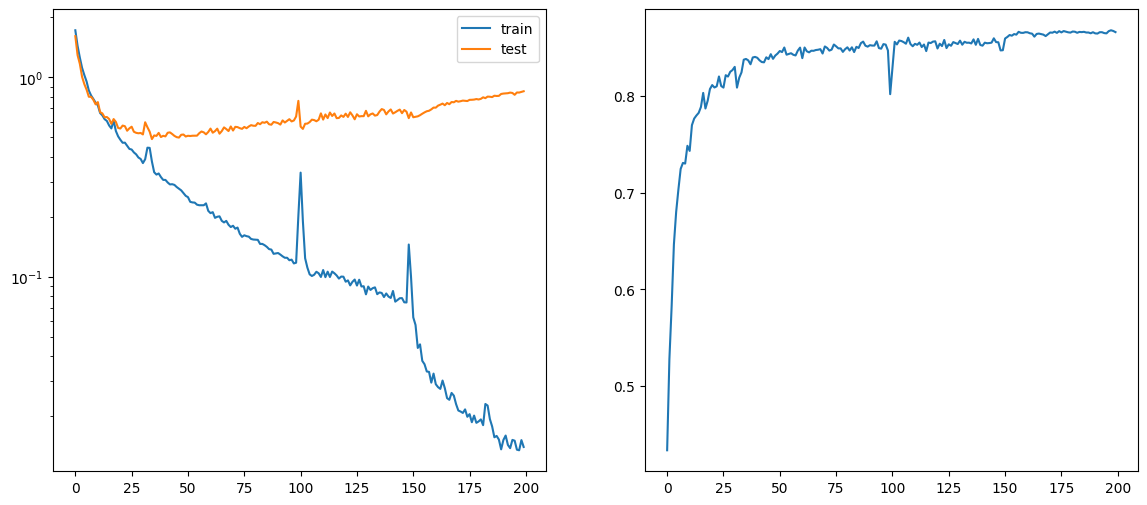

In [12]:
import matplotlib.pyplot as plt

dir_name=f'./exps/AdamW/Test/lr={lr:.0e}'
train_loss = np.load(f'{dir_name}/train_loss.npy')
test_loss = np.load(f'{dir_name}/test_loss.npy')
accuracy = np.load(f'{dir_name}/accuracy.npy')

fig, ax = plt.subplots(ncols=2, figsize=(14, 6))

ax[0].plot(train_loss, label='train')
ax[0].plot(test_loss, label='test')
ax[0].set_yscale('log')
ax[0].legend()

ax[1].plot(accuracy)